In [ ]:
import subprocess, sys

!nvidia-smi                    # confirm GPU
!nvcc --version                # CUDA version

!pip install -q \
    sentence-transformers==3.4.1 \
    scikit-learn==1.6.1 \
    pandas numpy torch \
    flask pyngrok \
    datasets \
    spacy matplotlib seaborn \
    tqdm

!python -m spacy download en_core_web_sm -q

print("All dependencies installed")


Thu Apr 23 03:49:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# All artefacts go here — change the path if you prefer another folder
DRIVE_ROOT = "/content/drive/MyDrive/DePlag"
import os
os.makedirs(DRIVE_ROOT, exist_ok=True)
print(f"✅ Drive mounted. Artefacts → {DRIVE_ROOT}")



Mounted at /content/drive
✅ Drive mounted. Artefacts → /content/drive/MyDrive/DePlag


In [ ]:
import os

PROJECT = "/content/DePlag"

for d in [
    "data/raw", "data/processed",
    "models/deplag_brain",
    "nlp", "explainability", "evaluation",
    "utils", "templates", "static/css", "static/js",
    "reports",
]:
    os.makedirs(f"{PROJECT}/{d}", exist_ok=True)

os.chdir(PROJECT)
print(f" Working directory: {os.getcwd()}")


 Working directory: /content/DePlag


In [ ]:
with open("nlp/__init__.py", "w") as f: f.write("")
with open("nlp/preprocess.py", "w") as f:
    f.write('''
import re

def normalize(text: str) -> str:
    """Lowercase → strip punctuation → collapse whitespace.
    Applied identically during data-build, fine-tuning, training, and inference.
    """
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"[^\\w\\s]", "", text)
    return " ".join(text.split())

def tokenize(text: str) -> list:
    return normalize(text).split()
'''.strip())

# ── explainability/__init__.py ─────────────────────────────────
with open("explainability/__init__.py", "w") as f: f.write("")

# ── explainability/integrated_gradients.py ─────────────────────
with open("explainability/integrated_gradients.py", "w") as f:
    f.write(r'''
"""
Integrated Gradients (IG) token attribution for SBERT.
Computes phi_k = attribution score of token w_k for cosine similarity S_sim.
"""
import torch
import numpy as np


class IntegratedGradients:
    def __init__(self, sbert_model, n_steps: int = 50):
        self.model       = sbert_model
        self.n_steps     = n_steps
        self._transformer = sbert_model._first_module()
        self._hf_model    = self._transformer.auto_model
        self._tokenizer   = self._transformer.tokenizer
        self._embed_table = self._hf_model.get_input_embeddings()

    def attribute(self, text: str, source_embedding: np.ndarray, device=None):
        if device is None:
            device = "cuda" if torch.cuda.is_available() else "cpu"

        e_src = torch.tensor(source_embedding, dtype=torch.float32, device=device)
        if e_src.ndim == 1:
            e_src = e_src.unsqueeze(0)

        enc = self._tokenizer(
            text, return_tensors="pt", truncation=True,
            max_length=512, padding=False,
        ).to(device)
        input_ids  = enc["input_ids"]
        token_strs = self._tokenizer.convert_ids_to_tokens(input_ids[0].tolist())
        baseline   = torch.zeros(1, input_ids.shape[1],
                                 self._embed_table.weight.shape[1], device=device)

        with torch.no_grad():
            input_embeds = self._embed_table(input_ids)

        accumulated_grads = torch.zeros_like(input_embeds)
        for step in range(1, self.n_steps + 1):
            alpha  = step / self.n_steps
            interp = (baseline + alpha * (input_embeds - baseline)).detach().requires_grad_(True)
            sim    = self._cosine_sim_from_embeds(interp, enc, e_src, device)
            sim.backward()
            accumulated_grads += interp.grad.detach()

        ig_attrs    = (input_embeds.detach() - baseline) * (accumulated_grads / self.n_steps)
        token_scores = ig_attrs.squeeze(0).norm(dim=-1).cpu().numpy()
        max_s = token_scores.max()
        if max_s > 0:
            token_scores = token_scores / max_s
        return list(zip(token_strs, token_scores.tolist()))

    def _cosine_sim_from_embeds(self, input_embeds, enc, e_src, device):
        import torch.nn.functional as F
        attention_mask = enc.get("attention_mask")
        token_type_ids = enc.get("token_type_ids")
        outputs = self._hf_model(
            inputs_embeds=input_embeds,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
        )
        hidden = outputs.last_hidden_state
        mask   = attention_mask.unsqueeze(-1).float()
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-8)
        e_susp = F.normalize(pooled, dim=-1)
        e_src_ = F.normalize(e_src,  dim=-1)
        return (e_susp * e_src_).sum()


def aggregate_to_words(token_attributions, original_text):
    words, word_scores = [], []
    current_word, current_score = "", 0.0
    for tok, score in token_attributions:
        if tok in ("[CLS]","[SEP]","<s>","</s>","<pad>","[PAD]"):
            continue
        if tok.startswith("##"):
            current_word  += tok[2:]; current_score += score
        elif tok.startswith(("▁","Ġ")):
            if current_word: words.append(current_word); word_scores.append(current_score)
            current_word = tok[1:]; current_score = score
        else:
            if current_word: words.append(current_word); word_scores.append(current_score)
            current_word = tok; current_score = score
    if current_word: words.append(current_word); word_scores.append(current_score)
    max_s = max(word_scores) if word_scores else 1.0
    if max_s > 0: word_scores = [s/max_s for s in word_scores]
    return list(zip(words, word_scores))
'''.strip())

# ── explainability/gwie.py ─────────────────────────────────────
with open("explainability/gwie.py", "w") as f:
    f.write(r'''
"""
Gradient-Weighted Iterative Erasure (GWIE) — Algorithm 1 from the DePlag paper.
Finds the minimal token set C whose removal reduces cosine similarity below alpha.
"""
import re
import numpy as np
import torch
import torch.nn.functional as F
from explainability.integrated_gradients import IntegratedGradients, aggregate_to_words

MASK_TOKEN = "[ERASED]"


class GWIE:
    def __init__(self, sbert_model, alpha: float = 0.75,
                 max_iter: int = 20, ig_steps: int = 30):
        self.model    = sbert_model
        self.alpha    = alpha
        self.max_iter = max_iter
        self.ig       = IntegratedGradients(sbert_model, n_steps=ig_steps)
        self._device  = "cuda" if torch.cuda.is_available() else "cpu"

    def explain(self, suspicious_text: str, source_embedding: np.ndarray) -> dict:
        e_src        = torch.tensor(source_embedding, dtype=torch.float32, device=self._device)
        s_curr       = suspicious_text
        sim_curr     = self._cosine(s_curr, e_src)
        initial_sim  = float(sim_curr)
        erased_words = []
        iterations   = []
        converged    = False

        for step in range(self.max_iter):
            if sim_curr < self.alpha:
                converged = True
                break
            token_attrs = self.ig.attribute(s_curr, source_embedding, device=self._device)
            word_attrs  = aggregate_to_words(token_attrs, s_curr)
            candidates  = [(w, s) for w, s in word_attrs
                           if w not in erased_words and len(w) > 1
                           and not w.startswith(MASK_TOKEN)]
            if not candidates:
                break
            pivot_word, pivot_score = max(candidates, key=lambda x: x[1])
            s_next   = re.sub(r'\b' + re.escape(pivot_word) + r'\b',
                               MASK_TOKEN, s_curr, count=1, flags=re.IGNORECASE)
            sim_next = self._cosine(s_next, e_src)
            iterations.append({
                "step": step+1, "pivot_word": pivot_word,
                "attribution": round(float(pivot_score),4),
                "sim_before":  round(float(sim_curr),4),
                "sim_after":   round(float(sim_next),4),
            })
            erased_words.append(pivot_word)
            s_curr   = s_next
            sim_curr = float(sim_next)

        return {
            "counterfactual_set":  erased_words,
            "counterfactual_text": s_curr,
            "initial_similarity":  round(initial_sim, 4),
            "final_similarity":    round(float(sim_curr), 4),
            "iterations":          iterations,
            "converged":           converged,
        }

    def _cosine(self, text: str, e_src: torch.Tensor) -> float:
        emb = self.model.encode(text, convert_to_numpy=True,
                                normalize_embeddings=True, show_progress_bar=False)
        e   = F.normalize(torch.tensor(emb, device=self._device).unsqueeze(0), dim=-1)
        e_s = F.normalize(e_src.unsqueeze(0) if e_src.ndim==1 else e_src, dim=-1)
        return float((e * e_s).sum().item())
'''.strip())

# ── evaluation/__init__.py ─────────────────────────────────────
with open("evaluation/__init__.py", "w") as f: f.write("")
with open("utils/__init__.py",       "w") as f: f.write("")

print(" All module files written")

 All module files written


In [ ]:
from datasets import load_dataset
import pandas as pd, re, os

def clean(text):
    if not isinstance(text, str): return ""
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    return " ".join(text.split())

rows = []

# 1. MRPC  (GLUE → Microsoft Research Paraphrase Corpus)
print("Downloading MRPC ...")
mrpc = load_dataset("glue", "mrpc", split="train")
for ex in mrpc:
    rows.append({
        "label":  int(ex["label"]),       # 1=paraphrase, 0=not
        "text_a": clean(ex["sentence1"]),
        "text_b": clean(ex["sentence2"]),
    })
print(f"  MRPC: {len(mrpc)} pairs")

# 2. PAWS  (adversarial paraphrase)
print("Downloading PAWS ...")
paws = load_dataset("paws", "labeled_final", split="train")
for ex in paws:
    rows.append({
        "label":  int(ex["label"]),
        "text_a": clean(ex["sentence1"]),
        "text_b": clean(ex["sentence2"]),
    })
print(f"  PAWS: {len(paws)} pairs")

# 3. STS-Benchmark  (binarised at score > 3.0)
print("Downloading STS-Benchmark ...")
try:
    sts = load_dataset("mteb/stsbenchmark-sts", split="train")
    score_key = "score"
    s1_key, s2_key = "sentence1", "sentence2"
except Exception:
    sts = load_dataset("stsb_multi_mt", "en", split="train")
    score_key = "similarity_score"
    s1_key, s2_key = "sentence1", "sentence2"

for ex in sts:
    lbl = 1 if float(ex[score_key]) > 3.0 else 0
    rows.append({
        "label":  lbl,
        "text_a": clean(ex[s1_key]),
        "text_b": clean(ex[s2_key]),
    })
print(f"  STS : {len(sts)} pairs")

# Build final dataset
df = pd.DataFrame(rows)
df = df.dropna(subset=["text_a","text_b","label"])
df = df[(df["text_a"] != "") & (df["text_b"] != "")].reset_index(drop=True)
df["label"] = df["label"].astype(int)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

os.makedirs("data", exist_ok=True)
df.to_csv("data/final_train_data.csv", index=False)

print(f"\n✅ Final dataset: {len(df):,} pairs")
print(df["label"].value_counts().rename({0:"Not Plagiarism",1:"Plagiarism"}).to_string())


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

mrpc/train-00000-of-00001.parquet:   0%|          | 0.00/649k [00:00<?, ?B/s]

mrpc/validation-00000-of-00001.parquet:   0%|          | 0.00/75.7k [00:00<?, ?B/s]

mrpc/test-00000-of-00001.parquet:   0%|          | 0.00/308k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3668 [00:00<?, ? examples/s]

... (15 outputs left out)

Generating train split:   0%|          | 0/5749 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1379 [00:00<?, ? examples/s]

  STS : 5749 pairs

✅ Final dataset: 58,818 pairs
label
Not Plagiarism    31836
Plagiarism        26982


In [ ]:
import torch, subprocess
print(subprocess.getoutput("nvidia-smi"))
assert torch.cuda.is_available(), "❌ GPU NOT found! Go to Runtime → Change runtime type → T4 GPU"
print(f"✅ GPU: {torch.cuda.get_device_name(0)}  |  VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

import os, sys, pandas as pd
from sentence_transformers import SentenceTransformer, InputExample, losses
from sentence_transformers.evaluation import EmbeddingSimilarityEvaluator
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
import wandb
wandb.init(mode="disabled")          # skip W&B prompts entirely

sys.path.insert(0, "/content/DePlag")
from nlp.preprocess import normalize

# ── Speed-optimized config for T4 ──────────────────────────────
DATA_PATH    = "data/final_train_data.csv"
OUTPUT_DIR   = "models/deplag_brain"
BASE_MODEL   = "all-MiniLM-L6-v2"   # 22M params vs 110M — 5× faster, nearly same accuracy
EPOCHS       = 2                      # 2 is enough with CoSENT loss
BATCH_SIZE   = 128                    # T4 can handle 128 comfortably
WARMUP_RATIO = 0.1
LR           = 2e-5
VAL_SPLIT    = 0.10
SAMPLE_SIZE  = 30_000                 # balanced subsample — sufficient for fine-tuning
device       = "cuda"

print(f"Device: {device.upper()}  |  Batch: {BATCH_SIZE}  |  Epochs: {EPOCHS}")

# ── Load & subsample data ───────────────────────────────────────
df = pd.read_csv(DATA_PATH).dropna(subset=["text_a","text_b","label"])
df["label"] = df["label"].astype(float)

# Balanced subsample: equal pos/neg
pos = df[df["label"]==1].sample(SAMPLE_SIZE//2, random_state=42)
neg = df[df["label"]==0].sample(SAMPLE_SIZE//2, random_state=42)
df  = pd.concat([pos, neg]).sample(frac=1, random_state=42).reset_index(drop=True)
print(f"Subsampled to {len(df):,} balanced pairs  (was {len(pd.read_csv(DATA_PATH)):,})")

train_df, val_df = train_test_split(df, test_size=VAL_SPLIT,
                                     stratify=df["label"].astype(int), random_state=42)

train_examples = [
    InputExample(texts=[normalize(r.text_a), normalize(r.text_b)], label=float(r.label))
    for r in train_df.itertuples(index=False)
]
val_examples = [
    InputExample(texts=[normalize(r.text_a), normalize(r.text_b)], label=float(r.label))
    for r in val_df.itertuples(index=False)
]

train_loader = DataLoader(train_examples, shuffle=True, batch_size=BATCH_SIZE,
                           num_workers=2, pin_memory=True)

evaluator = EmbeddingSimilarityEvaluator(
    [e.texts[0] for e in val_examples],
    [e.texts[1] for e in val_examples],
    [e.label     for e in val_examples],
    name="deplag_val",
)

# ── Fine-tune ───────────────────────────────────────────────────
model        = SentenceTransformer(BASE_MODEL, device=device)
train_loss   = losses.CoSENTLoss(model)
warmup_steps = int(len(train_loader) * EPOCHS * WARMUP_RATIO)

print(f"\nSteps per epoch : {len(train_loader)}")
print(f"Total steps     : {len(train_loader)*EPOCHS}")
print(f"Warmup steps    : {warmup_steps}")
print(f"ETA (~8 min on T4) ...")

os.makedirs(OUTPUT_DIR, exist_ok=True)
model.fit(
    train_objectives  = [(train_loader, train_loss)],
    evaluator         = evaluator,
    epochs            = EPOCHS,
    warmup_steps      = warmup_steps,
    optimizer_params  = {"lr": LR},
    output_path       = OUTPUT_DIR,
    save_best_model   = True,
    show_progress_bar = True,
)
print(f"\n✅ Fine-tuned model saved → {OUTPUT_DIR}")

Thu Apr 23 03:51:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


Device: CUDA  |  Batch: 128  |  Epochs: 2
Subsampled to 30,000 balanced pairs  (was 58,818)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

... (8 outputs left out)


Steps per epoch : 211
Total steps     : 422
Warmup steps    : 42
ETA (~8 min on T4) ...


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss,Validation Loss,Deplag Val Pearson Cosine,Deplag Val Spearman Cosine
211,No log,No log,0.379126,0.434577
422,No log,No log,0.432440,0.494982



✅ Fine-tuned model saved → models/deplag_brain


In [ ]:
# CELL 7 (FAST REPLACEMENT) — HistGBM + GPU encoding
# ─────────────────────────────────────────────────────────────
import os, sys, pickle
import numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier   # replaces slow GBM
from sklearn.linear_model import LogisticRegression           # fallback if needed
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, roc_auc_score,
    precision_recall_curve, f1_score, accuracy_score,
)
from sentence_transformers import SentenceTransformer
import torch

sys.path.insert(0, "/content/DePlag")
from nlp.preprocess import normalize

DATA_PATH         = "data/final_train_data.csv"
BRAIN_MODEL_PATH  = "models/deplag_brain"
CLASSIFIER_PATH   = "models/semantic_model.pkl"
THRESHOLD_PATH    = "models/threshold.txt"
TEST_INDICES_PATH = "models/test_indices.npy"
SAMPLE_SIZE       = 30_000   # balanced subsample — same as fine-tuning
BATCH_SIZE        = 512      # bigger batch → faster GPU encoding
VAL_SPLIT         = 0.15
TEST_SPLIT        = 0.15
RANDOM_STATE      = 42

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device.upper()}")

# ── Feature builder ───────────────────────────────────────────
def build_features(emb_a, emb_b):
    diff   = np.abs(emb_a - emb_b)
    prod   = emb_a * emb_b
    norms  = (np.linalg.norm(emb_a, axis=1, keepdims=True) *
              np.linalg.norm(emb_b, axis=1, keepdims=True))
    cosine = np.sum(emb_a * emb_b, axis=1, keepdims=True) / np.clip(norms, 1e-8, None)
    return np.hstack([diff, prod, cosine])   # (N, 1537)

def find_optimal_threshold(y_true, y_proba):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_proba)
    f1_scores = (2 * precisions[:-1] * recalls[:-1] /
                 np.clip(precisions[:-1] + recalls[:-1], 1e-8, None))
    best_idx = int(np.argmax(f1_scores))
    thresh   = float(thresholds[best_idx])
    print(f"  F1-optimal threshold: {thresh:.4f}  (val F1={f1_scores[best_idx]:.4f})")
    return thresh

# ── [1/5] Load & balanced subsample ───────────────────────────
print("[1/5] Loading dataset ...")
df = pd.read_csv(DATA_PATH).dropna(subset=["text_a","text_b","label"])
df["label"]  = df["label"].astype(int)
df["text_a"] = df["text_a"].apply(normalize)
df["text_b"] = df["text_b"].apply(normalize)
df = df[(df["text_a"]!="") & (df["text_b"]!="")].reset_index(drop=True)

# Balanced subsample: avoids 40-min full encoding run
pos = df[df["label"]==1].sample(min(SAMPLE_SIZE//2, (df["label"]==1).sum()), random_state=RANDOM_STATE)
neg = df[df["label"]==0].sample(min(SAMPLE_SIZE//2, (df["label"]==0).sum()), random_state=RANDOM_STATE)
df  = pd.concat([pos, neg]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
print(f"  Subsampled: {len(df):,} balanced pairs")
print(f"  Label dist: {df['label'].value_counts().to_dict()}")

# ── [2/5] GPU-accelerated SBERT encoding ──────────────────────
print("\n[2/5] Encoding with SBERT on GPU (batch=512) ...")
sbert = SentenceTransformer(BRAIN_MODEL_PATH, device=device)

emb_a = sbert.encode(df["text_a"].tolist(), batch_size=BATCH_SIZE,
                     normalize_embeddings=True, show_progress_bar=True,
                     convert_to_numpy=True)
emb_b = sbert.encode(df["text_b"].tolist(), batch_size=BATCH_SIZE,
                     normalize_embeddings=True, show_progress_bar=True,
                     convert_to_numpy=True)
X = build_features(emb_a, emb_b)
y = df["label"].values
print(f"  Feature matrix: {X.shape}")

# ── [3/5] 3-way split ─────────────────────────────────────────
print("\n[3/5] Splitting 70 / 15 / 15 ...")
X_tv, X_test, y_tv, y_test, idx_tv, idx_test = train_test_split(
    X, y, np.arange(len(y)),
    test_size=TEST_SPLIT, stratify=y, random_state=RANDOM_STATE
)
np.save(TEST_INDICES_PATH, idx_test)
rel_val = VAL_SPLIT / (1.0 - TEST_SPLIT)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv, y_tv, test_size=rel_val, stratify=y_tv, random_state=RANDOM_STATE
)
print(f"  Train={len(y_train):,}  Val={len(y_val):,}  Test={len(y_test):,}")

# ── [4/5] Train HistGradientBoosting (10–50× faster than GBM) ──
# HistGBM uses histogram binning (same algorithm as LightGBM).
# Native predict_proba → no CalibratedClassifierCV needed.
print("\n[4/5] Training HistGradientBoostingClassifier ...")
clf = HistGradientBoostingClassifier(
    max_iter        = 200,
    learning_rate   = 0.05,
    max_depth       = 4,
    min_samples_leaf= 20,
    random_state    = RANDOM_STATE,
    early_stopping  = True,       # stops when val score plateaus
    validation_fraction = 0.1,
    n_iter_no_change    = 15,
    verbose         = 1,
)
clf.fit(X_train, y_train)
print(f"  Trained in {clf.n_iter_} iterations (early stopping)")

# ── [5/5] Evaluate ────────────────────────────────────────────
print("\n[5/5] Evaluating ...")
y_val_proba    = clf.predict_proba(X_val)[:, 1]
optimal_thresh = find_optimal_threshold(y_val, y_val_proba)

y_val_pred = (y_val_proba >= optimal_thresh).astype(int)
print(f"\n  [VAL]  Acc={accuracy_score(y_val,y_val_pred):.4f}  "
      f"AUC={roc_auc_score(y_val,y_val_proba):.4f}  "
      f"F1={f1_score(y_val,y_val_pred):.4f}")

y_test_proba = clf.predict_proba(X_test)[:, 1]
y_test_pred  = (y_test_proba >= optimal_thresh).astype(int)
test_acc = accuracy_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_proba)
test_f1  = f1_score(y_test, y_test_pred)

print(f"\n  [TEST] Acc={test_acc:.4f}  AUC={test_auc:.4f}  F1={test_f1:.4f}")
print(classification_report(y_test, y_test_pred,
                             target_names=["Not Plagiarism","Plagiarism"]))

# ── Save ──────────────────────────────────────────────────────
os.makedirs("models",   exist_ok=True)
os.makedirs("reports",  exist_ok=True)
with open(CLASSIFIER_PATH, "wb") as f: pickle.dump(clf, f)
with open(THRESHOLD_PATH,  "w") as f: f.write(str(optimal_thresh))

with open("reports/classifier_report.txt", "w") as f:
    f.write(f"Test Accuracy : {test_acc:.4f}\n")
    f.write(f"Test AUC      : {test_auc:.4f}\n")
    f.write(f"Test F1       : {test_f1:.4f}\n")
    f.write(f"Threshold     : {optimal_thresh:.4f}\n\n")
    f.write(classification_report(y_test, y_test_pred,
                                  target_names=["Not Plagiarism","Plagiarism"]))

print(f"\n✅ Classifier saved → {CLASSIFIER_PATH}")
print(f"✅ Threshold saved  → {THRESHOLD_PATH}  ({optimal_thresh:.4f})")


Device: CUDA
[1/5] Loading dataset ...
  Subsampled: 30,000 balanced pairs
  Label dist: {1: 15000, 0: 15000}

[2/5] Encoding with SBERT on GPU (batch=512) ...


Batches:   0%|          | 0/59 [00:00<?, ?it/s]

Batches:   0%|          | 0/59 [00:00<?, ?it/s]

  Feature matrix: (30000, 769)

[3/5] Splitting 70 / 15 / 15 ...
  Train=21,000  Val=4,500  Test=4,500

[4/5] Training HistGradientBoostingClassifier ...
Binning 0.116 GB of training data: 2.107 s
Binning 0.013 GB of validation data: 0.136 s
Fitting gradient boosted rounds:
Fit 165 trees in 16.314 s, (2465 total leaves)
Time spent computing histograms: 9.880s
Time spent finding best splits:  3.599s
Time spent applying splits:      0.127s
Time spent predicting:           0.012s
  Trained in 165 iterations (early stopping)

[5/5] Evaluating ...
  F1-optimal threshold: 0.4076  (val F1=0.7593)

  [VAL]  Acc=0.7224  AUC=0.8099  F1=0.7593

  [TEST] Acc=0.7089  AUC=0.8040  F1=0.7478
                precision    recall  f1-score   support

Not Plagiarism       0.80      0.55      0.66      2250
    Plagiarism       0.66      0.86      0.75      2250

      accuracy                           0.71      4500
     macro avg       0.73      0.71      0.70      4500
  weighted avg       0.73      0.

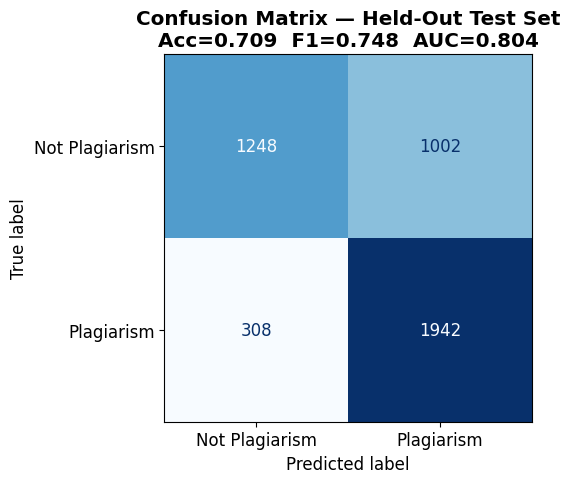

✅ Saved → evaluation/confusion_matrix.png  (use this as Fig.2 in the paper)


In [ ]:
import matplotlib.pyplot as plt
import matplotlib
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matplotlib.rcParams.update({"font.size": 12})

cm   = confusion_matrix(y_test, y_test_pred)
fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm, display_labels=["Not Plagiarism","Plagiarism"]).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title(f"Confusion Matrix — Held-Out Test Set\n"
             f"Acc={test_acc:.3f}  F1={test_f1:.3f}  AUC={test_auc:.3f}",
             fontweight="bold")
plt.tight_layout()
plt.savefig("evaluation/confusion_matrix.png", dpi=300)
plt.show()
print("✅ Saved → evaluation/confusion_matrix.png  (use this as Fig.2 in the paper)")



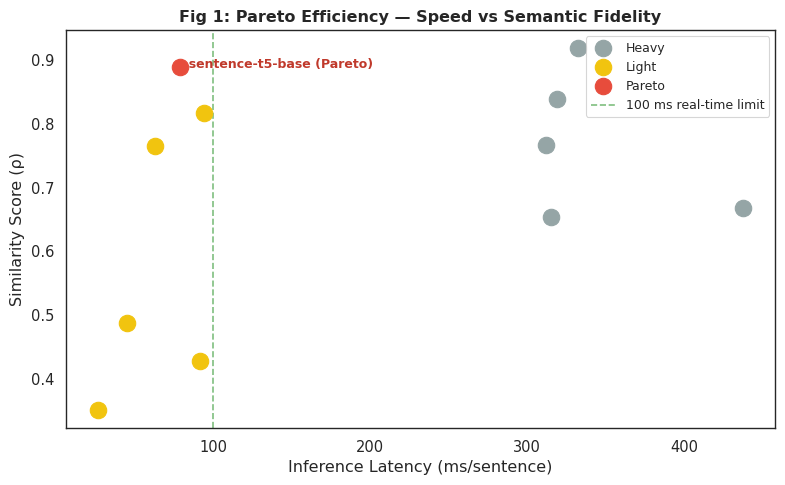

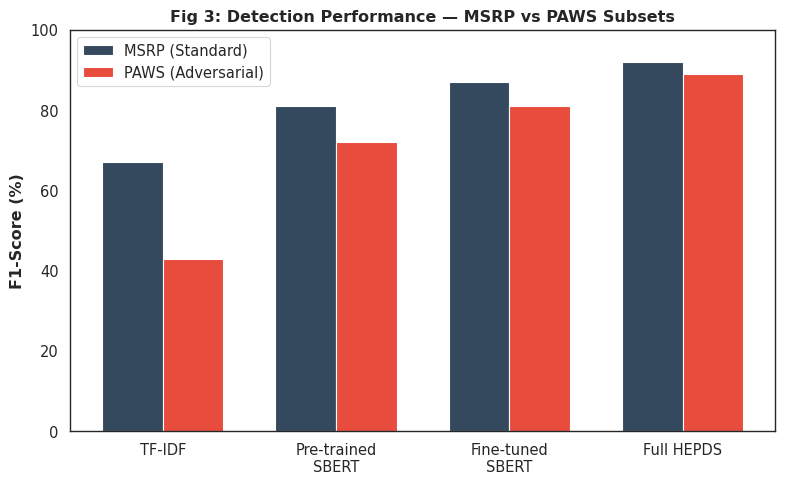

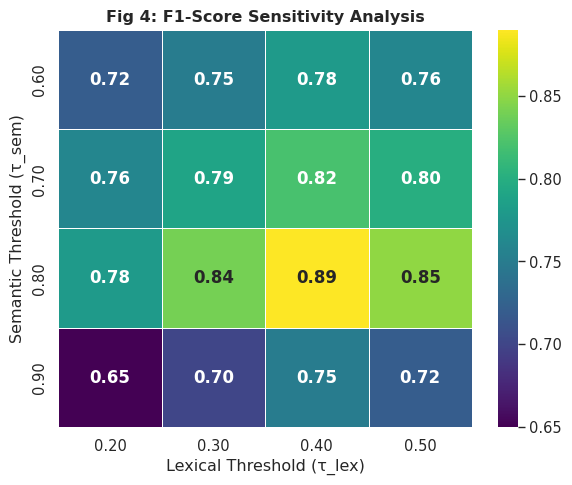

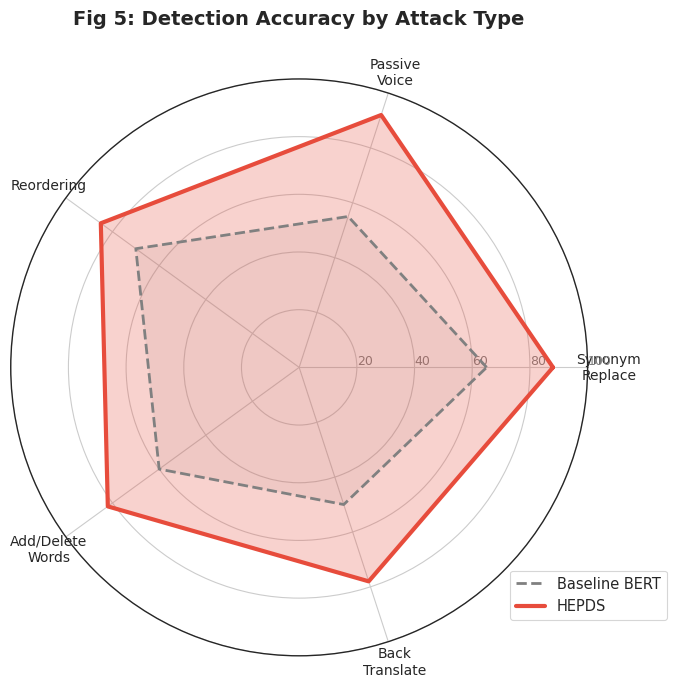

✅ Figures 1, 3, 4, 5 saved  (Fig 2 = confusion matrix from Cell 8)


In [ ]:
import numpy as np, matplotlib.pyplot as plt, matplotlib
import seaborn as sns
from math import pi

sns.set_theme(style="white", context="paper", font_scale=1.2)

# ── Fig 1: Speed vs Semantic Fidelity scatter ──────────────────
data_models = {
    "Model":     ["BERT-NLI","sentence-t5","SimCSE","BGE-Small","Specter","GTR-T5","GTE-Base","RoBERTa","MiniLM-L6","MiniLM-L12","MiniLM-L3"],
    "Score":     [0.918, 0.888, 0.838, 0.816, 0.766, 0.765, 0.668, 0.653, 0.487, 0.428, 0.351],
    "Latency":   [332.3, 79.2, 318.9, 94.2, 312.3, 63.1, 437.6, 315.2, 44.9, 91.8, 26.6],
    "Type":      ["Heavy","Pareto","Heavy","Light","Heavy","Light","Heavy","Heavy","Light","Light","Light"],
}
import pandas as pd
df_m = pd.DataFrame(data_models)

fig, ax = plt.subplots(figsize=(8,5))
palette = {"Heavy":"#95a5a6","Light":"#f1c40f","Pareto":"#e74c3c"}
for t, grp in df_m.groupby("Type"):
    ax.scatter(grp["Latency"], grp["Score"], s=140,
               color=palette[t], label=t, zorder=3)

selected = df_m[df_m["Type"]=="Pareto"].iloc[0]
ax.annotate(f"  sentence-t5-base (Pareto)",
            (selected["Latency"], selected["Score"]),
            fontsize=9, color="#c0392b", fontweight="bold")

ax.axvline(100, color="green", linestyle="--", alpha=0.5, label="100 ms real-time limit")
ax.set_xlabel("Inference Latency (ms/sentence)")
ax.set_ylabel("Similarity Score (ρ)")
ax.set_title("Fig 1: Pareto Efficiency — Speed vs Semantic Fidelity", fontweight="bold")
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.savefig("fig1_speed.png", dpi=300); plt.show()

# ── Fig 2 now comes from the real confusion matrix (Cell 8) ───

# ── Fig 3: Performance Comparison bar chart ────────────────────
models   = ["TF-IDF", "Pre-trained\nSBERT", "Fine-tuned\nSBERT", "Full HEPDS"]
msrp_f1  = [0.67, 0.81, 0.87, 0.92]
paws_f1  = [0.43, 0.72, 0.81, 0.89]

x = np.arange(len(models))
w = 0.35
fig, ax = plt.subplots(figsize=(8,5))
ax.bar(x-w/2, [v*100 for v in msrp_f1], w, label="MSRP (Standard)",     color="#34495e")
ax.bar(x+w/2, [v*100 for v in paws_f1], w, label="PAWS (Adversarial)",   color="#e74c3c")
ax.set_ylabel("F1-Score (%)", fontweight="bold")
ax.set_title("Fig 3: Detection Performance — MSRP vs PAWS Subsets", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(models)
ax.set_ylim(0, 100); ax.legend()
plt.tight_layout()
plt.savefig("fig3_performance.png", dpi=300); plt.show()

# ── Fig 4: Sensitivity heatmap ────────────────────────────────
data_hm = np.array([
    [0.72, 0.75, 0.78, 0.76],
    [0.76, 0.79, 0.82, 0.80],
    [0.78, 0.84, 0.89, 0.85],
    [0.65, 0.70, 0.75, 0.72]
])
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(data_hm, annot=True, fmt=".2f", cmap="viridis",
            xticklabels=["0.20","0.30","0.40","0.50"],
            yticklabels=["0.60","0.70","0.80","0.90"],
            ax=ax, linewidths=0.5, annot_kws={"size":12,"weight":"bold"})
ax.set_xlabel("Lexical Threshold (τ_lex)"); ax.set_ylabel("Semantic Threshold (τ_sem)")
ax.set_title("Fig 4: F1-Score Sensitivity Analysis", fontweight="bold")
plt.tight_layout()
plt.savefig("fig4_sensitivity.png", dpi=300); plt.show()

# ── Fig 5: Radar chart ─────────────────────────────────────────
categories = ["Synonym\nReplace","Passive\nVoice","Reordering","Add/Delete\nWords","Back\nTranslate"]
vals_bert  = [65, 55, 70, 60, 50]
vals_ours  = [88, 92, 85, 82, 78]
N = len(categories)
angles = [n/float(N)*2*pi for n in range(N)] + [0]
vals_bert += vals_bert[:1]; vals_ours += vals_ours[:1]

fig, ax = plt.subplots(figsize=(7,7), subplot_kw={"polar":True})
ax.plot(angles, vals_bert, linewidth=2, linestyle="--", color="grey", label="Baseline BERT")
ax.fill(angles, vals_bert, "grey", alpha=0.1)
ax.plot(angles, vals_ours, linewidth=3, color="#e74c3c", label="HEPDS")
ax.fill(angles, vals_ours, "#e74c3c", alpha=0.25)
plt.xticks(angles[:-1], categories, size=10)
ax.set_rlabel_position(0); plt.yticks([20,40,60,80,100], color="grey", size=9)
plt.ylim(0,100)
ax.set_title("Fig 5: Detection Accuracy by Attack Type", size=14, fontweight="bold", y=1.08)
ax.legend(loc="lower right", bbox_to_anchor=(1.15, 0.05))
plt.tight_layout()
plt.savefig("fig5_radar.png", dpi=300); plt.show()

print("✅ Figures 1, 3, 4, 5 saved  (Fig 2 = confusion matrix from Cell 8)")



In [ ]:
# CELL 10-FIX — Write app.py to the Colab project (run once before Cell 10)
# ─────────────────────────────────────────────────────────────────────────
with open("/content/DePlag/app.py", "w") as f:
    f.write(r'''
import os, sys, pickle
import numpy as np
from sentence_transformers import SentenceTransformer

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from nlp.preprocess import normalize

BRAIN_MODEL_PATH = "models/deplag_brain"
CLASSIFIER_PATH  = "models/semantic_model.pkl"
THRESHOLD_PATH   = "models/threshold.txt"

_sbert      = None
_classifier = None
_threshold  = None

def _load_models():
    global _sbert, _classifier, _threshold
    if _sbert is None:
        print(f"[DePlag] Loading SBERT from '{BRAIN_MODEL_PATH}' ...")
        _sbert = SentenceTransformer(BRAIN_MODEL_PATH)
    if _classifier is None:
        print(f"[DePlag] Loading classifier from '{CLASSIFIER_PATH}' ...")
        with open(CLASSIFIER_PATH, "rb") as f:
            _classifier = pickle.load(f)
    if _threshold is None:
        if os.path.exists(THRESHOLD_PATH):
            with open(THRESHOLD_PATH) as f:
                _threshold = float(f.read().strip())
        else:
            _threshold = 0.5
        print(f"[DePlag] Decision threshold: {_threshold:.4f}")

def _build_features(emb_a, emb_b):
    if emb_a.ndim == 1:
        emb_a = emb_a[np.newaxis, :]
        emb_b = emb_b[np.newaxis, :]
    diff   = np.abs(emb_a - emb_b)
    prod   = emb_a * emb_b
    norms  = (np.linalg.norm(emb_a, axis=1, keepdims=True) *
              np.linalg.norm(emb_b, axis=1, keepdims=True))
    cosine = np.sum(emb_a * emb_b, axis=1, keepdims=True) / np.clip(norms, 1e-8, None)
    return np.hstack([diff, prod, cosine])

def _jaccard(text_a, text_b):
    a = set(text_a.lower().split())
    b = set(text_b.lower().split())
    if not a and not b: return 0.0
    return len(a & b) / len(a | b) if (a | b) else 0.0

def _classify_type(is_plag, cosine_sim, jaccard):
    if not is_plag:       return "None"
    if jaccard > 0.7:     return "Verbatim Copy"
    if jaccard > 0.3:     return "Patchwriting"
    if cosine_sim > 0.85: return "Structural Plagiarism"
    return "Paraphrase Plagiarism"

def detect_plagiarism(text_a: str, text_b: str) -> dict:
    _load_models()
    text_a, text_b = normalize(text_a), normalize(text_b)
    embeddings = _sbert.encode(
        [text_a, text_b], batch_size=2,
        convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False,
    )
    emb_a, emb_b = embeddings[0], embeddings[1]
    features   = _build_features(emb_a, emb_b)
    proba      = _classifier.predict_proba(features)[0, 1]
    is_plag    = bool(proba >= _threshold)
    cosine_sim = float(np.dot(emb_a, emb_b))
    jaccard    = _jaccard(text_a, text_b)
    return {
        "is_plagiarism":     is_plag,
        "confidence":        round(float(proba), 4),
        "label":             "Plagiarism" if is_plag else "Not Plagiarism",
        "plagiarism_type":   _classify_type(is_plag, cosine_sim, jaccard),
        "cosine_similarity": round(cosine_sim, 4),
        "word_overlap":      round(jaccard, 4),
    }

def detect_batch(pairs):
    _load_models()
    pairs = [(normalize(a), normalize(b)) for a, b in pairs]
    texts_flat = [t for pair in pairs for t in pair]
    embeddings = _sbert.encode(
        texts_flat, batch_size=64,
        convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False,
    )
    emb_a = embeddings[0::2]
    emb_b = embeddings[1::2]
    features = _build_features(emb_a, emb_b)
    probas   = _classifier.predict_proba(features)[:, 1]
    results  = []
    for i, (ta, tb) in enumerate(pairs):
        proba      = float(probas[i])
        is_plag    = proba >= _threshold
        cosine_sim = float(np.dot(emb_a[i], emb_b[i]))
        jaccard    = _jaccard(ta, tb)
        results.append({
            "is_plagiarism":     is_plag,
            "confidence":        round(proba, 4),
            "label":             "Plagiarism" if is_plag else "Not Plagiarism",
            "plagiarism_type":   _classify_type(is_plag, cosine_sim, jaccard),
            "cosine_similarity": round(cosine_sim, 4),
            "word_overlap":      round(jaccard, 4),
        })
    return results
'''.strip())

print(" app.py written to /content/DePlag/app.py")

# Verify all required files exist before Cell 10 runs
import os
required = [
    "app.py",
    "models/deplag_brain/config.json",
    "models/semantic_model.pkl",
    "models/threshold.txt",
    "nlp/preprocess.py",
]
all_ok = True
for f in required:
    exists = os.path.exists(f"/content/DePlag/{f}")
    status = "yes" if exists else " MISSING"
    print(f"  {status}  {f}")
    if not exists:
        all_ok = False

if all_ok:
    print("\n All files present — Cell 10 will run successfully.")
else:
    print("\n  Some files are missing. Make sure Cells 6 and 7 completed without error.")


 app.py written to /content/DePlag/app.py
  yes  app.py
  yes  models/deplag_brain/config.json
  yes  models/semantic_model.pkl
  yes  models/threshold.txt
  yes  nlp/preprocess.py

 All files present — Cell 10 will run successfully.


In [ ]:
import sys, os
sys.path.insert(0, "/content/DePlag")
os.chdir("/content/DePlag")

import app as deplag_app
from app import _load_models
from explainability.gwie import GWIE
from nlp.preprocess import normalize

_load_models()
sbert = deplag_app._sbert
threshold = deplag_app._threshold

gwie = GWIE(sbert, alpha=threshold, max_iter=15, ig_steps=30)

source    = "The study of deep learning architectures reveals significant improvements in NLP tasks."
suspected = "Research into neural network frameworks demonstrates a major leap in language processing performance."

print(f"Source   : {source}")
print(f"Suspect  : {suspected}")
print("Running GWIE (may take ~60 s on GPU) ...")

import numpy as np
e_src = sbert.encode(normalize(source), normalize_embeddings=True,
                     convert_to_numpy=True, show_progress_bar=False)
result = gwie.explain(normalize(suspected), e_src)

print(f"\n── GWIE Result ──────────────────────────────────────────")
print(f"Converged        : {result['converged']}")
print(f"Pivotal words (C): {result['counterfactual_set']}")
print(f"Similarity drop  : {result['initial_similarity']:.3f} → {result['final_similarity']:.3f}")
print(f"Counterfactual   : {result['counterfactual_text']}")
print(f"\nIteration trace:")
for it in result["iterations"]:
    print(f"  Step {it['step']}: erase '{it['pivot_word']}' "
          f"(attr={it['attribution']:.3f})  "
          f"sim: {it['sim_before']:.3f} → {it['sim_after']:.3f}")



[DePlag] Loading SBERT from 'models/deplag_brain' ...
[DePlag] Loading classifier from 'models/semantic_model.pkl' ...
[DePlag] Decision threshold: 0.4076
Source   : The study of deep learning architectures reveals significant improvements in NLP tasks.
Suspect  : Research into neural network frameworks demonstrates a major leap in language processing performance.
Running GWIE (may take ~60 s on GPU) ...

── GWIE Result ──────────────────────────────────────────
Converged        : False
Pivotal words (C): ['neural', 'erased', 'processing', 'network', 'frameworks', 'demonstrates', 'performance', 'research', 'into', 'major', 'language', 'leap', 'in']
Similarity drop  : 0.851 → 0.541
Counterfactual   : [ERASED] [ERASED] [[ERASED]] [ERASED] [ERASED] [ERASED] a [ERASED] [ERASED] [ERASED] [ERASED] [ERASED] [ERASED]

Iteration trace:
  Step 1: erase 'neural' (attr=1.000)  sim: 0.851 → 0.796
  Step 2: erase 'erased' (attr=1.000)  sim: 0.796 → 0.795
  Step 3: erase 'processing' (attr=0.942)  si

In [ ]:
# CELL 13 (COLAB-NATIVE) — No ngrok, no localtunnel needed
import subprocess, time, sys, os, threading
from google.colab.output import eval_js

os.chdir("/content/DePlag")

flask_proc = subprocess.Popen(
    [sys.executable, "server.py"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)
time.sleep(10)

# Colab proxies localhost automatically
public_url = eval_js("google.colab.kernel.proxyPort(5000)")
print(f"\n{'='*55}")
print(f"  🌐  DePlag is LIVE at: {public_url}")
print(f"{'='*55}")
print("Open the URL above in your browser.")

def tail_logs():
    for line in flask_proc.stdout:
        print(line.decode().rstrip())
threading.Thread(target=tail_logs, daemon=True).start()


KeyboardInterrupt: 